# Ex4: ANN on satellite patches

Kernel: **ml4space**. RGB inputs come from Lab 3 crops in `ex1/satellite_images`, true color in the Sentinel 2 style.

Goal: build a simple ANN that classifies 200×200 patches. This notebook covers Task 1 and Task 2.


## Shared setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

IMG_DIR = Path("../ex1/satellite_images")
PATCH = 200
rng = np.random.default_rng(42)

print("TF", tf.__version__)

TF 2.21.0


# Task 1: urban versus forest with Sentinel 2 RGB

### As a function

$$
f: \mathbb{R}^{200 \times 200 \times 3} \rightarrow \{0 = \text{forest},\ 1 = \text{urban}\}
$$

The ANN learns an approximation of $f$ from labeled patches.


### Training data
We take random 200×200 crops from the forest and urban images and add flips.

Each patch is turned into a spectral feature vector: RGB means, standard deviations, and percentiles. A barebone Dense net is a poor fit for the raw $200 \times 200 \times 3$ tensor with $120\,000$ values.


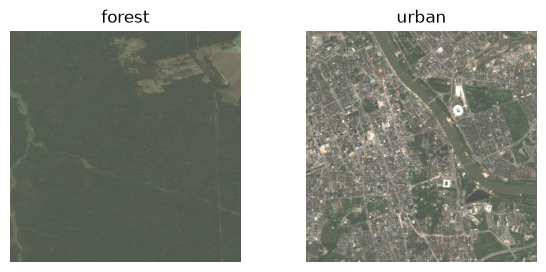

patches: (160, 15) train/test: (112, 15) (48, 15)


In [2]:
def load_rgb(name):
    return np.asarray(Image.open(IMG_DIR / name).convert("RGB"), dtype=np.float32) / 255.0

def patch_features(patch):
    # 3 mean + 3 std + 9 percentiles (25/50/75 x 3) = 15
    return np.concatenate([
        patch.mean(axis=(0, 1)),
        patch.std(axis=(0, 1)),
        np.percentile(patch.reshape(-1, 3), [25, 50, 75], axis=0).ravel(),
    ]).astype(np.float32)

def sample_patches(img, n, label):
    h, w, _ = img.shape
    X, y = [], []
    for _ in range(n):
        yy = rng.integers(0, h - PATCH + 1)
        xx = rng.integers(0, w - PATCH + 1)
        p = img[yy:yy + PATCH, xx:xx + PATCH]
        if rng.random() < 0.5:
            p = np.fliplr(p)
        if rng.random() < 0.5:
            p = np.flipud(p)
        X.append(patch_features(p))
        y.append(label)
    return np.asarray(X), np.asarray(y)

forest = load_rgb("forest_poland.jpg")
urban = load_rgb("urban_poland.jpg")

X_f, y_f = sample_patches(forest, 80, 0)
X_u, y_u = sample_patches(urban, 80, 1)
X1 = np.vstack([X_f, X_u])
y1 = np.concatenate([y_f, y_u])

Xtr, Xte, ytr, yte = train_test_split(
    X1, y1, test_size=0.3, random_state=0, stratify=y1
)
scaler1 = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler1.transform(Xtr), scaler1.transform(Xte)

fig, ax = plt.subplots(1, 2, figsize=(7, 3))
ax[0].imshow(forest); ax[0].set_title("forest"); ax[0].axis("off")
ax[1].imshow(urban);  ax[1].set_title("urban");  ax[1].axis("off")
plt.show()
print("patches:", X1.shape, "train and test:", Xtr_s.shape, Xte_s.shape)

### Barebone architecture
Input size 15, then Dense with 8 ReLU units, then Dense with 1 sigmoid unit. Loss is binary cross entropy. Optimizer is Adam.


In [3]:
def make_model(n_features, hidden, activation="relu", lr=1e-2, opt="adam"):
    layers = [tf.keras.Input(shape=(n_features,))]
    for u in hidden:
        layers.append(tf.keras.layers.Dense(u, activation=activation))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    if opt == "adam":
        optimizer = tf.keras.optimizers.Adam(lr)
    elif opt == "sgd":
        optimizer = tf.keras.optimizers.SGD(lr, momentum=0.9)
    else:
        optimizer = tf.keras.optimizers.RMSprop(lr)
    model.compile(loss="binary_crossentropy", optimizer=optimizer, metrics=["accuracy"])
    return model

def train_eval(name, hidden, activation="relu", lr=1e-2, opt="adam", epochs=40,
               Xtr=None, Xte=None, y_train=None, y_test=None):
    Xtr = Xtr_s if Xtr is None else Xtr
    Xte = Xte_s if Xte is None else Xte
    y_train = ytr if y_train is None else y_train
    y_test = yte if y_test is None else y_test
    tf.keras.utils.set_random_seed(42)
    model = make_model(Xtr.shape[1], hidden, activation, lr, opt)
    hist = model.fit(Xtr, y_train, epochs=epochs, validation_split=0.2, verbose=0)
    loss, acc = model.evaluate(Xte, y_test, verbose=0)
    yhat = (model.predict(Xte, verbose=0).ravel() >= 0.5).astype(int)
    return {
        "name": name,
        "hidden": hidden,
        "act": activation,
        "opt": f"{opt}({lr})",
        "epochs": epochs,
        "acc": float(acc),
        "loss": float(loss),
        "hist": hist.history,
        "yhat": yhat,
        "model": model,
    }

### At least five architecture and optimizer permutations

,name,hidden,act,opt,epochs,acc,loss
0,T1 barebone,[8],relu,adam(0.01),40,1.0,0.002320
1,T1 wider,[64],relu,adam(0.01),40,1.0,0.000034
2,T1 deeper,"[32, 16]",relu,adam(0.01),40,1.0,0.000004
3,T1 tanh,[32],tanh,adam(0.01),40,1.0,0.000287
4,T1 SGD,[32],relu,sgd(0.05),40,1.0,0.000086
5,T1 RMSprop,[32],relu,rmsprop(0.01),40,1.0,0.000023


              precision    recall  f1-score   support

      forest       1.00      1.00      1.00        24
       urban       1.00      1.00      1.00        24

    accuracy                           1.00        48
   macro avg       1.00      1.00      1.00        48
weighted avg       1.00      1.00      1.00        48

CM:
 [[24  0]
 [ 0 24]]


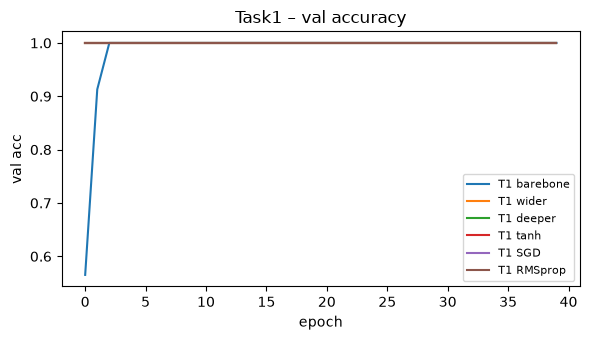

In [4]:
exps1 = [
    train_eval("T1 barebone", [8], activation="relu", opt="adam", lr=1e-2),
    train_eval("T1 wider", [64], activation="relu", opt="adam", lr=1e-2),
    train_eval("T1 deeper", [32, 16], activation="relu", opt="adam", lr=1e-2),
    train_eval("T1 tanh", [32], activation="tanh", opt="adam", lr=1e-2),
    train_eval("T1 SGD", [32], activation="relu", opt="sgd", lr=5e-2),
    train_eval("T1 RMSprop", [32], activation="relu", opt="rmsprop", lr=1e-2),
]

df1 = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "yhat", "model")} for r in exps1])
display(df1)

best1 = max(exps1, key=lambda r: r["acc"])
print(classification_report(yte, best1["yhat"], target_names=["forest", "urban"]))
print("CM:\n", confusion_matrix(yte, best1["yhat"]))

plt.figure(figsize=(6, 3.5))
for r in exps1:
    plt.plot(r["hist"]["val_accuracy"], label=r["name"])
plt.xlabel("epoch"); plt.ylabel("val acc"); plt.legend(fontsize=8); plt.title("Task 1 val accuracy"); plt.tight_layout(); plt.show()

### Findings for Task 1
The problem is a map from patch to class, so an ANN is valid.
On these crops the classes separate well in spectral space, so accuracy stays high even with the barebone net.
Wider or deeper nets help little here. The data are simple, and a bigger model overfits more easily when patches are few.
A Bayesian classifier from Lab 3 can still be preferable: the set is small, the PDF is explicit, decisions are easy to read, and there is little tuning. ANNs tend to win on large or complex data, not on two easy classes with simple features.


# Task 2: season from Sentinel 5P pollutants over Warsaw

We use real TROPOMI S5P Level 2 Cloud Optimized GeoTIFFs from the public AWS bucket `s3://meeo-s5p`.
Channels are tropospheric NO₂, total CO, and total O₃, cropped to the Warsaw bbox from 20.5E to 21.6E and 51.8N to 52.5N, then resampled to $200 \times 200$.

Winter scenes are January 2024 orbits with coverage.
Summer scenes are July 2024 orbits with coverage.

Local cache: `data/s5p/*.npy` with channel order NO₂, CO, O₃.
To fetch again, run `download_s5p_warsaw.py`.

### As a function

$$
g: \mathbb{R}^{200 \times 200 \times 3} \rightarrow \{0 = \text{winter},\ 1 = \text{summer}\}
$$


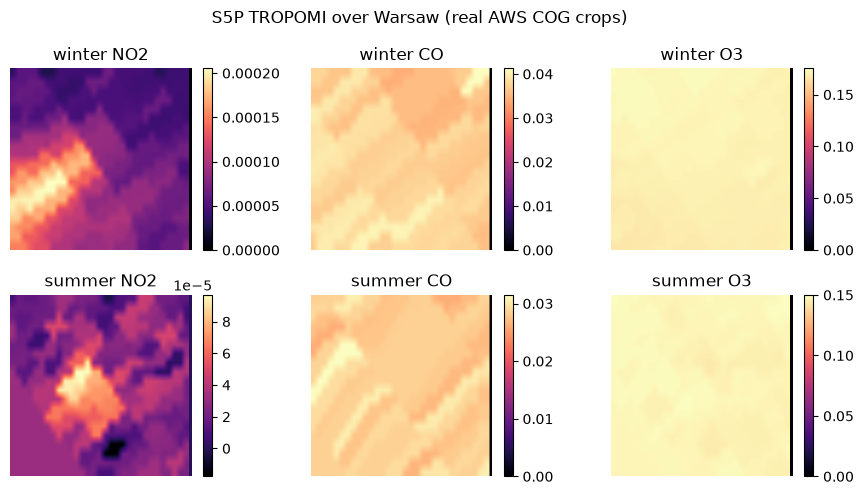

scenes: 12 winter + 12 summer
feature samples: (96, 12) train/test: (67, 12) (29, 12)
mean feature by class (winter/summer):
 winter [1.1056776e-04 3.6578130e-02 1.4537725e-01] (NO2/CO/O3 means)
 summer [3.2288637e-05 3.0461729e-02 1.4195830e-01] (NO2/CO/O3 means)


In [5]:
S5P_DIR = Path("data/s5p")
POLLUTANTS = ["NO2", "CO", "O3"]

def load_s5p_scenes():
    X, y = [], []
    for f in sorted(S5P_DIR.glob("*.npy")):
        arr = np.load(f).astype(np.float32)  # (200, 200, 3)
        if arr.ndim != 3 or arr.shape[-1] != 3:
            continue
        label = 0 if f.name.startswith("winter") else 1
        # flips as light augmentation for more patch samples
        variants = [arr, np.fliplr(arr), np.flipud(arr), np.fliplr(np.flipud(arr))]
        for v in variants:
            feat = np.concatenate([
                v.mean(axis=(0, 1)),
                v.std(axis=(0, 1)),
                np.percentile(v.reshape(-1, 3), [25, 75], axis=0).ravel(),
            ])
            X.append(feat)
            y.append(label)
    return np.asarray(X, dtype=np.float32), np.asarray(y)

X2, y2 = load_s5p_scenes()
assert len(X2) > 0, "No S5P files in data/s5p — run download_s5p_warsaw.py"

Xtr2, Xte2, ytr2, yte2 = train_test_split(
    X2, y2, test_size=0.3, random_state=1, stratify=y2
)
scaler2 = StandardScaler().fit(Xtr2)
Xtr2_s, Xte2_s = scaler2.transform(Xtr2), scaler2.transform(Xte2)

# preview one winter / summer scene
w_files = sorted(S5P_DIR.glob("winter_*.npy"))
s_files = sorted(S5P_DIR.glob("summer_*.npy"))
w_scene, s_scene = np.load(w_files[0]), np.load(s_files[0])

fig, ax = plt.subplots(2, 3, figsize=(9, 5))
for i, name in enumerate(POLLUTANTS):
    im0 = ax[0, i].imshow(w_scene[..., i], cmap="magma")
    ax[0, i].set_title(f"winter {name}"); ax[0, i].axis("off"); plt.colorbar(im0, ax=ax[0, i], fraction=0.046)
    im1 = ax[1, i].imshow(s_scene[..., i], cmap="magma")
    ax[1, i].set_title(f"summer {name}"); ax[1, i].axis("off"); plt.colorbar(im1, ax=ax[1, i], fraction=0.046)
plt.suptitle("S5P TROPOMI over Warsaw, real AWS COG crops"); plt.tight_layout(); plt.show()

print("scenes:", len(w_files), "winter and", len(s_files), "summer")
print("feature samples:", X2.shape, "train and test:", Xtr2_s.shape, Xte2_s.shape)
print("mean feature by class, winter then summer:")
print(" winter NO2 CO O3 means:", X2[y2 == 0].mean(axis=0)[:3])
print(" summer NO2 CO O3 means:", X2[y2 == 1].mean(axis=0)[:3])


### Barebone model and at least five permutations, same recipe as Task 1

,name,hidden,act,opt,epochs,acc,loss
0,T2 barebone,[8],relu,adam(0.01),40,1.0,0.008847
1,T2 wider,[64],relu,adam(0.01),40,1.0,0.000823
2,T2 deeper,"[32, 16]",relu,adam(0.01),40,1.0,0.000141
3,T2 tanh,[32],tanh,adam(0.01),40,1.0,0.003708
4,T2 SGD,[32],relu,sgd(0.05),40,1.0,0.003249
5,T2 RMSprop,[32],relu,rmsprop(0.01),40,1.0,0.000513


              precision    recall  f1-score   support

      winter       1.00      1.00      1.00        14
      summer       1.00      1.00      1.00        15

    accuracy                           1.00        29
   macro avg       1.00      1.00      1.00        29
weighted avg       1.00      1.00      1.00        29



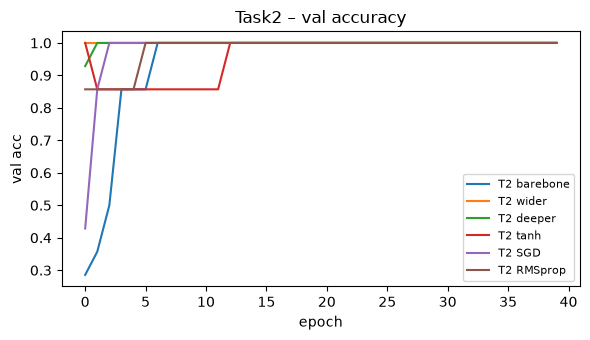

In [6]:
def train_eval2(name, hidden, activation="relu", lr=1e-2, opt="adam", epochs=40):
    return train_eval(
        name, hidden, activation, lr, opt, epochs,
        Xtr=Xtr2_s, Xte=Xte2_s, y_train=ytr2, y_test=yte2,
    )

exps2 = [
    train_eval2("T2 barebone", [8], activation="relu", opt="adam", lr=1e-2),
    train_eval2("T2 wider", [64], activation="relu", opt="adam", lr=1e-2),
    train_eval2("T2 deeper", [32, 16], activation="relu", opt="adam", lr=1e-2),
    train_eval2("T2 tanh", [32], activation="tanh", opt="adam", lr=1e-2),
    train_eval2("T2 SGD", [32], activation="relu", opt="sgd", lr=5e-2),
    train_eval2("T2 RMSprop", [32], activation="relu", opt="rmsprop", lr=1e-2),
]

df2 = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "yhat", "model")} for r in exps2])
display(df2)

best2 = max(exps2, key=lambda r: r["acc"])
print(classification_report(yte2, best2["yhat"], target_names=["winter", "summer"]))

plt.figure(figsize=(6, 3.5))
for r in exps2:
    plt.plot(r["hist"]["val_accuracy"], label=r["name"])
plt.xlabel("epoch"); plt.ylabel("val acc"); plt.legend(fontsize=8); plt.title("Task 2 val accuracy"); plt.tight_layout(); plt.show()

### Findings for Task 2
Season is cast as a map from an S5P patch to winter or summer.
The inputs are real Sentinel 5P Level 2 crops over Warsaw from AWS `meeo-s5p`, January against July 2024.
Native TROPOMI sampling over this bbox is coarse, about 20 by 30 cells, so we resample to $200\times200$ as the brief asks.
Winter NO₂ is usually higher than in summer. That seasonal contrast is what the ANN can use.
A barebone net is often enough. Deeper nets are not automatically better on a small Earth observation set.


## Summary

| | Task 1 | Task 2 |
|--|--|--|
| function | RGB patch to forest or urban | S5P patch to winter or summer |
| data | `ex1/satellite_images` | real S5P crops in `data/s5p` |
| ANN input | 15 spectral features | 12 pollutant features |
| barebone | Dense 8 then sigmoid | Dense 8 then sigmoid |
| experiments | 6 variants of layers, activation, optimizer | same |

**Takeaway:** an ANN fits when the task is a map from data to a label. On small Earth observation sets with simple features, Bayes or kNN from Lab 3 are often simpler and still strong enough.
